# Copula aggregation, tail dependence and the Euler allocation

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the simple sum and the square-root rule)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- state what a copula is (Sklar's theorem), draw uniforms with the Gaussian and the Student t copula and say what tail dependence is, with the closed form of the t and Clayton coefficients;
- turn the four marginals of Banco Andino into a simulation of the four losses and read the VaR, expected shortfall and economic capital of their sum;
- see why the Student t copula asks for more capital than the Gaussian one at the same correlation, and by how much at each degree of freedom;
- allocate the expected shortfall of the total to the four risks with the Euler principle, check that the contributions add up exactly, and compare with the closed-form allocation of the square-root rule;
- say honestly how the committed band rows were produced and what this notebook's simulation does and does not reproduce of them.

## Setup

Install the pinned notebook environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or install only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds the whole environment, `.venv-notebooks`, for you. A notebook never installs anything by itself. The engine's test identifiers are printed as the engine writes them. Its messages and notes are written in English: this tree prints them as written, and the Spanish tree prints a translation from a table in the notebook that fails if the engine changes the text.

The next cell imports what the notebook uses and prints the versions of the packages, so that you can compare them with the pins.

In [1]:
# Import the engine and the helpers, and print the versions of the packages this notebook uses
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from scipy import stats
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import simple
from riskvalidation.portfolio import euler
from riskvalidation.portfolio import portfolio as rv_port
from riskvalidation.validation import portfolio as port_tests
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

This notebook reads the same case as notebook 01, **C18** (Banco Andino).

- **Owner and licence:** the documents are written by this repository's offline pipeline (`data-pipeline/pipeline/cases/c18/`) with the engine `riskvalidation` and committed under `data/derived/C18/`. The scenario paths come from the Federal Reserve (public domain), the EBA and ESRB (reproduction authorised with the source acknowledged) and the NGFS (derived-only: only the few variables the case uses). **Banco Andino is a synthetic bank**: its book and capital are calibrated to public aggregates, and the scenario paths are real United States and euro-area paths transposed onto its jump-off, so the satellites are a US-calibrated adaptation.
- **Truth status:** `synthetic-calibrated`. There is no answer key for the bank; the checks of this notebook are recomputations of committed numbers with the engine, not comparisons with a published result.
- **Baked by:** `riskvalidation` 0.8.1 (seed 42), the version this notebook installs, so a recomputation is expected to match to rounding.
- **Files read:** `data/derived/C18/baseline.json` (`outputs.aggregation`: the marginals, the correlation matrix, the set of degrees of freedom, the committed band and the committed Euler allocation), `data/derived/C18/t-copula-baseline.json` (the same block with the market-credit correlation stress) and `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`: the quantile function of each of the four marginals on a named probability grid, contract `c18-models` 3.0.0).
- **How the committed rows were made.** The pipeline builds a sample of one million losses for each marginal with the engine (credit: the grouped copula of the C07 segments; market: a Student t fitted to the VaR and ES of C11; interest rate risk: the Hull-White simulation of C15; operational risk: the Fourier aggregation of the C17 generator), hands the four quantile functions to `dependence_band`, and commits the result. **The four samples are not committed, but each marginal's quantile function is**, on a named grid: the 1,961 probabilities $\Phi(z)$ for $z$ from -4.9 to 4.9 in steps of 0.005, dense in both tails. Step 3 rebuilds the four marginals from the grids by linear interpolation in the probability, the rule the aggregation applies to the sorted sample, and step 4 runs the pipeline's own aggregation on them with the pipeline's seed, so the committed rows are expected back almost to the digit. The committed rows are always printed beside the notebook's own.

In [2]:
# The notebook sits three folders below the repository root; a missing file stops the notebook and names its path
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


print("derived folder found:", DERIVED.is_dir())

baseline = read_json("C18/baseline.json")
agg = baseline["outputs"]["aggregation"]
risks = [m["risk"] for m in agg["marginals"]]
R = np.array(agg["correlation"]["matrix"])
NU_SET = agg["nu_set"]["values"]
print("risks:", risks, "| nu set:", NU_SET, "| baked by riskvalidation", baseline["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

derived folder found: True
risks: ['credit', 'market', 'irrbb', 'operational'] | nu set: [4.0, 8.0, 30.0] | baked by riskvalidation 0.9.0 | installed 0.9.0


## Method

### Step 1: a copula and its tail dependence

**Sklar's theorem.** Any joint distribution of losses $L_1, \dots, L_d$ with marginal distribution functions $F_k$ can be written $F(x_1, \dots, x_d) = C(F_1(x_1), \dots, F_d(x_d))$, where the copula $C$ carries all the dependence and the $F_k$ carry all the marginal behaviour. Aggregation by copula therefore has three parts: choose the marginals, choose $C$, and simulate $L_k = F_k^{-1}(U_k)$ with $U \sim C$ (dossier 05, G.1 item 3; McNeil, Frey and Embrechts 2015, whose chapter number is UNVERIFIED in the dossier).

- **Gaussian copula** with correlation matrix $R$: $U = \Phi(Z)$ with $Z \sim N(0, R)$ (Li 2000). It has no tail dependence for $|\rho| < 1$: extremes of the two risks become independent far enough into the tail.
- **Student t copula** with $\nu$ degrees of freedom: $U = t_\nu(X)$ with $X = \sqrt{\nu / \chi^2_\nu}\, Z$ (Frey and McNeil 2003; Demarta and McNeil 2005). Its bivariate **tail dependence coefficient**, the limit of $P(U_2 > q \mid U_1 > q)$ as $q \to 1$, is
$$\lambda = 2\, t_{\nu+1}\!\left(-\sqrt{\frac{(\nu+1)(1-\rho)}{1+\rho}}\right).$$
- **Clayton copula** (bivariate): $C_\theta(u, v) = (u^{-\theta} + v^{-\theta} - 1)^{-1/\theta}$ with $\theta > 0$, and lower tail dependence $\lambda_L = 2^{-1/\theta}$. The engine has the closed forms of Clayton but does not sample it (the module's docstring defers Clayton sampling and vine copulas).

The next cell evaluates the t coefficient at the market-credit correlation of the case (0.5) for each degree of freedom of the case, and the Clayton closed forms at three values of $\theta$.

In [3]:
# The t tail dependence at correlation 0.5 for each nu of the case, and the Clayton closed forms
for nu in NU_SET:
    print(f"t copula, rho = 0.5, nu = {nu:4.0f}: tail dependence = {cop.t_tail_dependence(0.5, nu):.4f}")
print("t copula, rho = 0.5, nu = 1000 (nearly Gaussian):", format(cop.t_tail_dependence(0.5, 1000.0), ".2e"))
for theta in (0.5, 1.0, 2.0):
    print(f"Clayton theta = {theta}: C(0.5, 0.5) = {cop.clayton_copula(0.5, 0.5, theta):.4f} | lower tail dependence = {cop.clayton_lower_tail_dependence(theta):.4f}")

t copula, rho = 0.5, nu =    4: tail dependence = 0.2532
t copula, rho = 0.5, nu =    8: tail dependence = 0.1173
t copula, rho = 0.5, nu =   30: tail dependence = 0.0030
t copula, rho = 0.5, nu = 1000 (nearly Gaussian): 1.48e-64
Clayton theta = 0.5: C(0.5, 0.5) = 0.2991 | lower tail dependence = 0.2500
Clayton theta = 1.0: C(0.5, 0.5) = 0.3333 | lower tail dependence = 0.5000
Clayton theta = 2.0: C(0.5, 0.5) = 0.3780 | lower tail dependence = 0.7071


### Step 2: drawing uniforms and measuring the tail

`simulate_copula_uniforms(corr, family, nu, n, seed)` returns $n \times K$ uniforms with the copula of the matrix `corr`. Both families give the same rank correlation: the Kendall $\tau$ of a pair is $(2/\pi)\arcsin\rho$, 0.3333 for $\rho = 0.5$, so a rank statistic cannot tell the copulas apart. What differs is the corner. The next cell draws one million pairs from each copula at $\rho = 0.5$, estimates $P(U_2 > q \mid U_1 > q)$ at $q = 0.9, 0.99, 0.999$ by counting, and compares with the limit of step 1. The sample is seeded, so the numbers repeat.

In [4]:
# Draw one million pairs from the Gaussian and the t(4) copula at rho = 0.5 and count joint exceedances
pair = np.array([[1.0, 0.5], [0.5, 1.0]])
N_PAIRS = 1_000_000
draws = {"Gaussian": cop.simulate_copula_uniforms(pair, "gaussian", None, N_PAIRS, 7),
         "t (nu=4)": cop.simulate_copula_uniforms(pair, "t", 4.0, N_PAIRS, 7)}
print("Kendall tau of the pair, theory:", round(2 / np.pi * np.arcsin(0.5), 4))
for name, u in draws.items():
    tau = stats.kendalltau(u[:20_000, 0], u[:20_000, 1])[0]
    estimates = []
    for q in (0.9, 0.99, 0.999):
        first = u[:, 0] > q
        estimates.append(float((u[first, 1] > q).mean()))
    print(f"{name:9s} Kendall tau (20000 pairs): {tau:.4f} | P(U2 > q | U1 > q) at q = 0.9, 0.99, 0.999: {np.round(estimates, 4)}")
print("limit for t(4):", round(cop.t_tail_dependence(0.5, 4.0), 4), "| limit for the Gaussian: 0")

Kendall tau of the pair, theory: 0.3333
Gaussian  Kendall tau (20000 pairs): 0.3367 | P(U2 > q | U1 > q) at q = 0.9, 0.99, 0.999: [0.3222 0.1278 0.0552]
t (nu=4)  Kendall tau (20000 pairs): 0.3386 | P(U2 > q | U1 > q) at q = 0.9, 0.99, 0.999: [0.3849 0.2816 0.2784]
limit for t(4): 0.2532 | limit for the Gaussian: 0


The picture shows the same thing: the two clouds have the same centre and the same Kendall $\tau$, but the t copula puts visibly more points in the upper-right and lower-left corners, which for losses is the corner where both risks go wrong together.

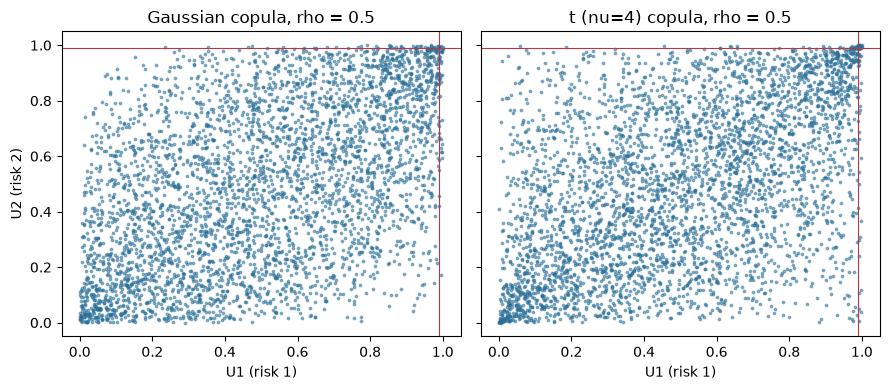

In [5]:
# Scatter 4,000 pairs of each copula, with the joint-exceedance corner marked
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, (name, u) in zip(axes, draws.items()):
    ax.scatter(u[:4000, 0], u[:4000, 1], s=3, alpha=0.5, color="#2a6f97")
    ax.axvline(0.99, color="#b23a48", linewidth=0.8)
    ax.axhline(0.99, color="#b23a48", linewidth=0.8)
    ax.set_title(f"{name} copula, rho = 0.5")
    ax.set_xlabel("U1 (risk 1)")
axes[0].set_ylabel("U2 (risk 2)")
fig.tight_layout()
plt.show()

### Step 3: the marginals

The copula needs a quantile function $F_k^{-1}$ for each risk, and the case commits them. For each marginal the models document holds its quantile at the probabilities $\Phi(z)$, $z = -4.9, -4.895, \dots, 4.9$ (1,961 points, in CLP millions), from about $5 \times 10^{-7}$ to $1 - 5 \times 10^{-7}$, the reach of the first and last of the $10^6$ draws. Between two points the quantile function is linear in the probability and clamped at the ends, which is the rule of the engine's `marginal_ppf_sample` applied to a sorted sample. Nothing is fitted: the shape of every marginal, the heavy tail of operational risk included, is the pipeline's.

The next cell rebuilds the four quantile functions, reads a sample of $10^6$ Hazen positions $(i - 0.5)/n$ from each, and prints the VaR, the ES and the mean that the engine's estimators read from it beside the committed VaR, ES and expected loss.

In [6]:
# Rebuild the four marginals from the committed quantile grids and compare what the engine reads from them with the committed EL, VaR and ES
LEVEL = 0.999
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
probs = np.array(grid["probabilities"])
draw_positions = (np.arange(1, 1_000_001) - 0.5) / 1_000_000
ppfs, samples = [], {}
for m, q in zip(agg["marginals"], grid["marginals"]):
    assert m["risk"] == q["risk"]
    quantiles = np.array(q["quantiles"])
    ppfs.append(lambda u, x=quantiles: np.interp(np.asarray(u, dtype=float), probs, x))
    samples[m["risk"]] = np.interp(draw_positions, probs, quantiles)
print("grid:", grid["convention"]["name"], "|", grid["convention"]["points"], "points | z from", grid["convention"]["z_min"], "to", grid["convention"]["z_max"], "in steps of", grid["convention"]["z_step"], "| first and last probability:", probs[0], probs[-1])
print(f'{"risk":12s} {"VaR here":>10s} {"VaR committed":>14s} {"ES here":>10s} {"ES committed":>13s} {"ES gap":>8s} {"mean here":>10s} {"EL committed":>13s}')
for m in agg["marginals"]:
    sample = samples[m["risk"]]
    var_here, es_here = rv_port.var_from_sample(sample, LEVEL), rv_port.es_from_sample(sample, LEVEL)
    print(f'{m["risk"]:12s} {var_here:10,.0f} {m["var_clp_m"]:14,.0f} {es_here:10,.0f} {m["es_clp_m"]:13,.0f} {es_here / m["es_clp_m"] - 1:8.1%} {sample.mean():10,.0f} {m["el_clp_m"]:13,.0f}')

grid: standard-normal-z-grid | 1961 points | z from -4.9 to 4.9 in steps of 0.005 | first and last probability: 4.791832765903185e-07 0.9999995208167234
risk           VaR here  VaR committed    ES here  ES committed   ES gap  mean here  EL committed
credit          298,239        298,227    346,964       346,949     0.0%     37,694        37,619
market          283,436        283,435    355,807       355,803     0.0%          0             0
irrbb           100,747        100,746    106,381       106,382    -0.0%     27,922        27,922
operational      42,357         42,367    173,668       171,091     1.5%      1,168         1,188


### Step 4: simulate the four losses and aggregate

`simulate_component_losses(ppfs, corr, family, nu, n_draws, seed, chunk_size)` draws the uniforms of step 2 for the four risks and maps each through its quantile function, giving an $n \times 4$ matrix of losses $L_k = F_k^{-1}(U_k)$. The total of a scenario is the row sum. `copula_aggregate` does the same and returns the VaR, the ES and the economic capital $EC = \mathrm{VaR} - \sum_k \mathrm{EL}_k$ of the total, with their Monte Carlo standard errors (batch means). The next cell prints the first rows of one simulation, checks that the row sum is the total, and runs the five aggregations of the case (Gaussian, and t at each $\nu$) with the pipeline's own settings: one million draws, chunks of 100,000, seed 42. The committed row and the ratio to it are printed beside each.

In [7]:
# One simulation shown row by row, then the five aggregations of the case beside the committed band rows
SEED, CHUNK, N_DRAWS = 42, 100_000, 1_000_000
el_total = sum(m["el_clp_m"] for m in agg["marginals"])
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, N_DRAWS, SEED, CHUNK)
total = joint.sum(axis=1)
print("simulated losses (first 3 scenarios), CLP millions:")
print(np.round(joint[:3], 0), "| row sums:", np.round(total[:3], 0))
print("sum of the four expected losses:", round(el_total, 1))
committed = {(r["method"], r["nu"]): r for r in agg["band"]}
print(f'{"copula":14s} {"EC here":>10s} {"MC se":>8s} {"committed":>10s} {"here / committed":>16s}')
here = {}
for family, nu in (("gaussian", None), *(("t", v) for v in NU_SET)):
    result = cop.copula_aggregate(ppfs, R, family, nu, el_total, LEVEL, N_DRAWS, SEED, CHUNK)
    key = ("gaussian-copula", None) if family == "gaussian" else ("t-copula", nu)
    here[key] = result
    print(f'{family + ("" if nu is None else f" nu={nu:g}"):14s} {result.ec:10,.0f} {result.var_se:8,.0f} {committed[key]["capital_clp_m"]:10,.0f} {result.ec / committed[key]["capital_clp_m"]:16.3f}')

simulated losses (first 3 scenarios), CLP millions:
[[  34585.  -40953.   41628.    1244.]
 [   1959. -141702.   -6731.     376.]
 [  24746.  -40887.   41590.    1070.]] | row sums: [  36504. -146098.   26519.]
sum of the four expected losses: 66728.7
copula            EC here    MC se  committed here / committed
gaussian          491,999    2,554    491,974            1.000
t nu=4            552,369    3,430    552,389            1.000
t nu=8            528,318    2,794    528,321            1.000
t nu=30           499,133    3,281    499,128            1.000


How to read the comparison. Rebuilt from the committed grids, with the pipeline's seed, the four rows land on the committed ones: the ratios are 1.000 to three decimals and the largest difference is 25 CLP millions (the Gaussian row), against a Monte Carlo standard error of 2,554 on it. What is left is the linear interpolation between grid points and the grid's reach, 4.8e-7 from each end. The **ordering** is the committed one: Gaussian at the bottom, then t with $\nu = 30$, then $\nu = 8$, then $\nu = 4$. A fatter-tailed copula asks for more capital at the same correlation and the same marginals, and the lower the degrees of freedom, the more. This is the content of the engine's `copula_choice_sensitivity` test (notebook 07).

In [8]:
# Print the ordering of the five aggregations here and in the committed band, and the relative gap to the Gaussian row
order_here = sorted(here, key=lambda k: here[k].ec)
order_committed = sorted(here, key=lambda k: committed[k]["capital_clp_m"])
print("ordering here     :", [("Gaussian" if k[1] is None else f"t{k[1]:g}") for k in order_here])
print("ordering committed:", [("Gaussian" if k[1] is None else f"t{k[1]:g}") for k in order_committed])
base_here, base_committed = here[("gaussian-copula", None)].ec, committed[("gaussian-copula", None)]["capital_clp_m"]
for k in here:
    if k[1] is not None:
        print(f"t nu={k[1]:g}: above the Gaussian row by {here[k].ec / base_here - 1:6.1%} here and {committed[k]['capital_clp_m'] / base_committed - 1:6.1%} in the committed band")

ordering here     : ['Gaussian', 't30', 't8', 't4']
ordering committed: ['Gaussian', 't30', 't8', 't4']
t nu=4: above the Gaussian row by  12.3% here and  12.3% in the committed band
t nu=8: above the Gaussian row by   7.4% here and   7.4% in the committed band
t nu=30: above the Gaussian row by   1.5% here and   1.5% in the committed band


### Step 5: the Euler allocation of the expected shortfall

A total of $d$ risks can be split into $d$ contributions that add up to it. For a risk measure $\rho$ that is positively homogeneous of degree one, the **Euler contribution** of risk $k$ is the derivative of the total's measure when the size of risk $k$ grows, $\rho(L_k \mid L) = \frac{d}{dh}\rho(L + h L_k)\big|_{h=0}$, and the contributions add up to $\rho(L)$ (Tasche 2007, Definition 2.2 and Remark 2.1). For the expected shortfall the contribution is a conditional mean,

$$\mathrm{ES}_\alpha(L_k \mid L) = E\,[L_k \mid L \ge \mathrm{VaR}_\alpha(L)],$$

and the engine's `es_contributions` estimates it from the sample with the Acerbi-Tasche weights, so that the contributions add up to the sample ES exactly. The contribution of the VaR conditions on one point and is very noisy in simulation, which is why the case allocates the ES. The next cell allocates the ES of the Gaussian aggregate of step 4, runs the engine's additivity test, and prints each risk's share beside the committed share. The **Euler benefit** of a risk is $1 - \mathrm{ES}(L_k \mid L)/\mathrm{ES}(L_k)$.

In [9]:
# Allocate the ES of the Gaussian aggregate, test additivity, and compare shares and benefits with the committed allocation
es_total = rv_port.es_from_sample(total, LEVEL)
contributions = euler.es_contributions(joint, total, LEVEL)
additivity = port_tests.euler_additivity(contributions, es_total, 1e-6, model_id="notebook")
print("ES of the total here:", round(es_total, 1), "| committed:", round(agg["euler"]["es_total_clp_m"], 1))
print("additivity test:", additivity.light.value, "| relative gap:", additivity.metric)
committed_share = {row["risk"]: row["share"] for row in agg["euler"]["allocation"]}
print(f'{"risk":12s} {"contribution":>13s} {"share here":>10s} {"share committed":>16s} {"benefit here":>13s}')
for k, m in enumerate(agg["marginals"]):
    standalone_es = rv_port.es_from_sample(joint[:, k], LEVEL)
    print(f'{m["risk"]:12s} {contributions[k]:13,.0f} {contributions[k] / es_total:10.3f} {committed_share[m["risk"]]:16.3f} {simple.euler_diversification_benefit(contributions[k], standalone_es):13.3f}')

ES of the total here: 709402.6 | committed: 709390.0
additivity test: green | relative gap: 0.0
risk          contribution share here  share committed  benefit here
credit             254,924      0.359            0.359         0.264
market             275,997      0.389            0.389         0.225
irrbb               78,543      0.111            0.111         0.263
operational         99,939      0.141            0.141         0.458


The allocation adds up to the total exactly, because the weights are built to. Its **values depend on the tails of the marginals**, and here the tails are the pipeline's: the total ES is 709,403 against the committed 709,390, and the shares equal the committed ones to three decimals (credit 0.359, market 0.389, interest rate risk 0.111, operational risk 0.141). Operational risk carries 14 percent of the tail of the total while its capital is 6 percent of the simple sum, because its marginal is heavy-tailed (its committed ES is four times its VaR). An allocation is only as good as the tails it was computed on, and these are the committed ones.

**The closed-form allocation of the square-root rule.** For the variance-covariance total there is no simulation: with $\Sigma_{jk} = R_{jk}\,EC_j\,EC_k$ the standard-deviation measure $\sqrt{\mathbf 1^{\top}\Sigma\,\mathbf 1}$ is homogeneous and its Euler contributions are $c\,\mathrm{cov}[L_k, L]/\sqrt{\mathrm{var}[L]} = (\Sigma\mathbf 1)_k / \sqrt{\mathbf 1^{\top}\Sigma\mathbf 1}$ (Tasche 2007, equation 3.4). `std_contributions` computes them. The next cell allocates the square-root total of notebook 01 this way and checks that the contributions add up to it.

In [10]:
# The closed-form Euler allocation of the variance-covariance total, and its additivity
ec = np.array([m["ec_clp_m"] for m in agg["marginals"]])
sigma = R * np.outer(ec, ec)
std_parts = simple.std_contributions(sigma)
total_vc = simple.variance_covariance(ec, R)
print("variance-covariance total:", round(total_vc, 3), "| sum of the contributions:", round(float(std_parts.sum()), 3))
for m, part, own in zip(agg["marginals"], std_parts, ec):
    print(f'{m["risk"]:12s} contribution {part:10,.0f} | stand-alone EC {own:10,.0f} | Euler benefit {simple.euler_diversification_benefit(part, own):.3f}')

variance-covariance total: 528106.395 | sum of the contributions: 528106.395
credit       contribution    220,570 | stand-alone EC    260,607 | Euler benefit 0.154
market       contribution    246,017 | stand-alone EC    283,435 | Euler benefit 0.132
irrbb        contribution     48,688 | stand-alone EC     72,824 | Euler benefit 0.331
operational  contribution     12,831 | stand-alone EC     41,179 | Euler benefit 0.688


## Results

The next cell draws the five aggregations of this notebook and of the committed band side by side, with the simple sum and the square-root total as reference lines.

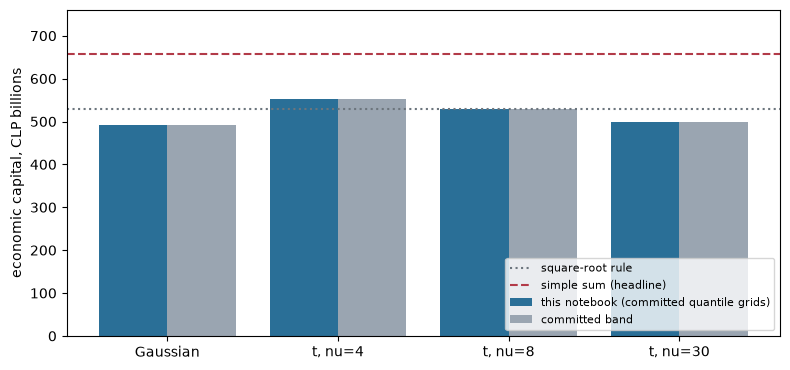

In [11]:
# Draw the five copula aggregations here and in the committed band, with the two closed-form rows as reference lines
keys = list(here)
names = ["Gaussian" if k[1] is None else f"t, nu={k[1]:g}" for k in keys]
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(x - 0.2, [here[k].ec / 1e3 for k in keys], width=0.4, label="this notebook (committed quantile grids)", color="#2a6f97")
ax.bar(x + 0.2, [committed[k]["capital_clp_m"] / 1e3 for k in keys], width=0.4, label="committed band", color="#9aa5b1")
ax.axhline(total_vc / 1e3, color="#6c757d", linestyle=":", label="square-root rule")
ax.axhline(agg["headline"]["capital_clp_m"] / 1e3, color="#b23a48", linestyle="--", label="simple sum (headline)")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("economic capital, CLP billions")
ax.set_ylim(0, 760)
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

- **The t coefficient falls fast with the degrees of freedom:** 0.2532 at $\nu = 4$, 0.1173 at $\nu = 8$ and 0.0030 at $\nu = 30$, which is why $\nu = 30$ is the case's stand-in for the Gaussian copula. In the simulation, the chance that the second risk also exceeds its 99.9 percent quantile given that the first does is 0.055 for the Gaussian copula and 0.278 for the t copula with $\nu = 4$; with a million draws only about a thousand pairs reach that corner, so the estimate is a picture of the limit and not a measurement of it.
- **The rebuilt marginals read back as committed.** From the grids the engine reads the committed VaR to within 0.03 percent (credit 298,239 against 298,227; operational risk 42,357 against 42,367) and the committed ES to within 0.01 percent for credit, market and interest rate risk; the ES of operational risk is 1.5 percent above the committed one (173,668 against 171,091), because the committed figure is the engine's `es_for_severity` on the severity grid and this one is the ES of a million-point sample of the interpolated grid.
- **The four aggregations reproduce the committed rows**: 491,999, 552,369, 528,318 and 499,133 against 491,974, 552,389, 528,321 and 499,128 (ratios 1.000 for the Gaussian copula and for the t copulas with $\nu = 4$, 8 and 30), differences of 25, -20, -3 and 5 CLP millions against Monte Carlo standard errors of 2,554 to 3,430, and **the ordering is the committed one**: Gaussian, t with $\nu = 30$, 8, then 4. The t rows lie 1.5, 7.4 and 12.3 percent above the Gaussian row, here and in the committed band.
- **The ES allocation adds up exactly** (relative gap 0.0). The total ES is 709,403 against the committed 709,390, and the shares are the committed ones: credit 35.9 percent, market 38.9, interest rate risk 11.1 and operational risk 14.1 percent.
- **The closed-form allocation of the square-root rule adds up to 528,106**, the notebook 01 total, and gives Euler benefits of 15.4 percent (credit), 13.2 percent (market), 33.1 percent (interest rate risk) and 68.8 percent (operational risk): the smaller the risk, the larger its benefit.

What this notebook does not show: the million-draw samples themselves, which are not committed, so the marginals come from a grid of 1,961 points and the rows agree to 0.01 percent and not to the last digit; the Clayton copula, evaluated in closed form only because the engine does not sample it; and the Gaussian and t rows are conditional on the correlation matrix, a convention, whose stress is read in notebook 07.

## Summary

- A copula separates the dependence from the marginals (Sklar); aggregation is: choose the marginals, choose the copula, simulate $L_k = F_k^{-1}(U_k)$ and read the VaR, ES and EC of the row sum.
- The Gaussian and the t copula share the same rank correlation but not the corner: the t has tail dependence $\lambda = 2\,t_{\nu+1}(\cdot)$, the Gaussian none, and a simulation shows the difference.
- The committed models document keeps each marginal's quantile function on a named grid, not the million losses; this notebook rebuilt the marginals from it and the committed rows came back to within 0.01 percent, in the committed order.
- The Euler allocation of the ES adds up to the total exactly and gives each risk a benefit; the square-root rule has a closed-form allocation that adds up too.

**What to try next.** Change the seed of step 4 and watch the capital move by about its standard error; then continue with notebook 03, which adds the two bounds that do not depend on any copula: the best and worst VaR over every dependence.

## References

- Rosenberg, J. V. and Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. and Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Tasche, D. (2007), Capital allocation to business units and sub-portfolios: the Euler principle (arXiv 0708.2542). https://arxiv.org/abs/0708.2542
- Embrechts, P., McNeil, A. and Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, in Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Li, D. X. (2000), the Gaussian copula and Frey, R. and McNeil, A. J. (2003) and Demarta, S. and McNeil, A. J. (2005), the t copula, as cited by the engine's `riskvalidation.aggregation.copulas` module docstring.
- This repository: `docs/contracts/engine/aggregation-api.md`.